# 马尔可夫决策过程

## 简介
马尔可夫决策过程(Markov
Reward
Process) 是强化学习的基础。要学习好强化学习我们首先得明确掌握马尔可夫决策过程的基础知识。我们通常说的强化学习中的环境一般就是一个马尔可夫决策过程。与多臂老虎机不同，马尔可夫决策过程包含了状态信息以及状态之间的转移机制。如果我们要用强化学习去解决一个实际问题，我们第一步要做的事情就是能够把这个实际问题抽象为一个马尔可夫决策过程，也就是明确马尔可夫决策过程的各个组成要素。在本节内容中，我们将从马尔可夫过程出发，一步一步进行介绍，最后引出马尔可夫决策过程。

## 马尔可夫奖励过程（Markov Reward Process）
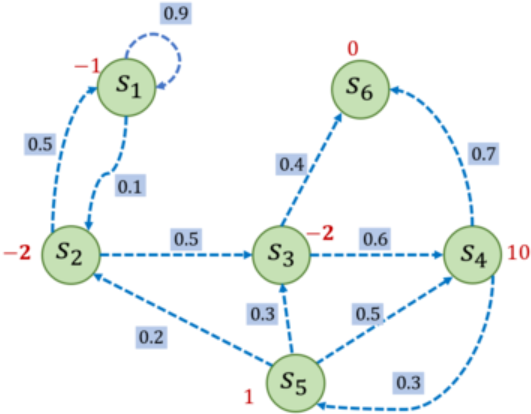
接下来我们将图中马尔可夫奖励过程用代码表示，并且定义计算回报的函数。
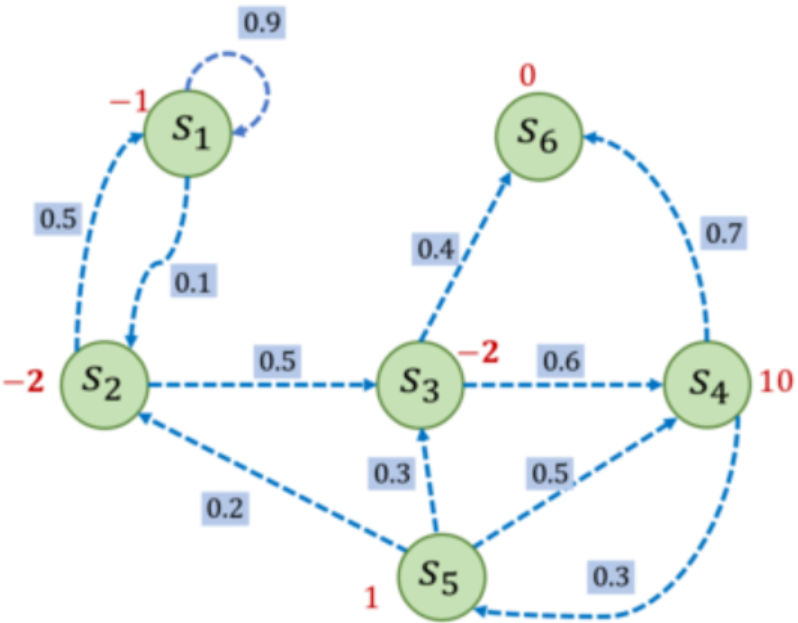
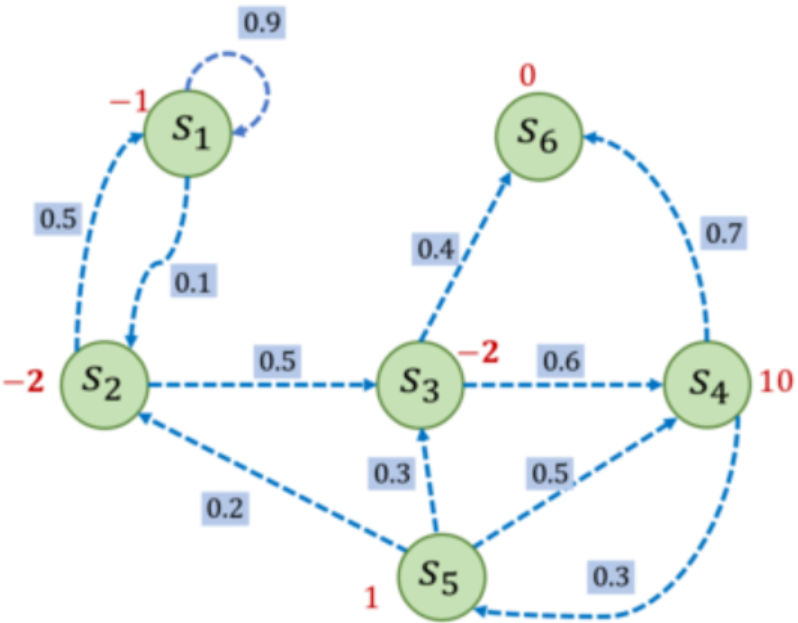
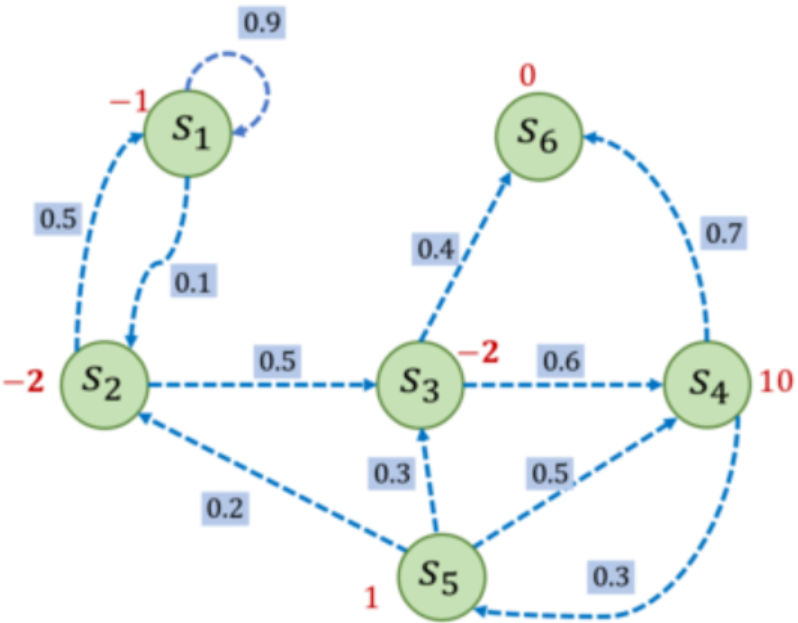
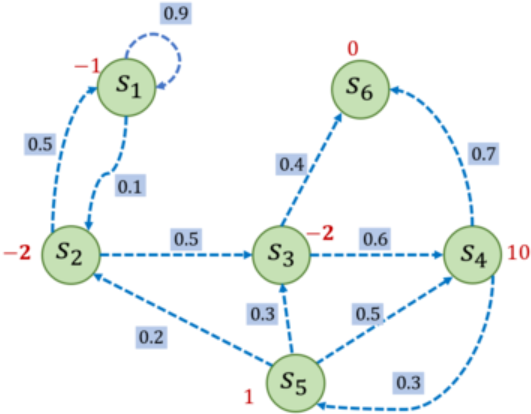
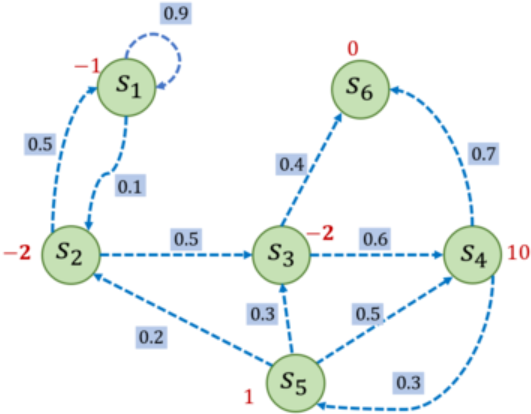

In [50]:
# 导包
import numpy as np
np.random.seed(0)       # 固定随机种子

# 定义状态转移概率矩阵P
P = [
    [0.9, 0.1, 0.0, 0.0, 0.0, 0.0],
    [0.5, 0.0, 0.5, 0.0, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.6, 0.0, 0.4],
    [0.0, 0.0, 0.0, 0.0, 0.3, 0.7],
    [0.0, 0.2, 0.3, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.0, 0.0, 1.0]
]
P = np.array(P)     # 转成numpy形式的数组

rewards = [-1, -2, -2, 10, 1, 0]        # 定义奖励函数（解释：分别代表了走到不同状态时获得的奖励值）
gamma = 0.5         # 定义折扣因子

# 给定一条序列，计算从某个索引开始到序列最后得到的回报
# 参1：起始索引；参2：状态序列；参3：折扣因子γ
def compute_return(start_index, chain, gamma):
    G = 0       # 定义初始回报为 0
    for i in reversed(range(start_index, len(chain))):      # range(start_index, len(chain)) = range(0, 4)，reversed表示反向遍历
        # 回报计算公式：G_t = R_t + γ * R_t+1 + γ^2 * R_t+2 + γ^3 * R_t+3 + ...
        # 递推式：G_t+1 = R_t+1 + γ * R_t+2 + γ^2 * R_t+3 + γ^3 * R_t+4 + ... -> G_t = R_t + γ * G_t+1，所以遍历是反向的
        G = rewards[chain[i] - 1] + gamma * G       # chain[i] - 1：chain 中定义的状态的索引是从 1 开始，而 rewards 中是从 0 开始
    return G

In [51]:
# 一个状态序列：s1-s2-s3-s6
chain = [1, 2, 3, 6]
start_index = 0     # 定义起始索引为0，将s1作为起始位置
G = compute_return(start_index, chain, gamma)       # 计算从s1开始，沿s1-s2-s3-s6走完得到的回报
print("根据本序列计算得到回报为：", G)       # G = -1 + 0.5 * (-2) + 0.5^2 * (-2) + 0.5^3 * 0 = -1 - 1 - 0.5 = -2.5

根据本序列计算得到回报为： -2.5


### 价值函数（Value Function）
我们接下来将求解价值函数的解析解方法用代码写出来，并据此计算上图中MRP中所有状态的价值。

In [52]:
def compute(P, rewards, gamma, states_num):
    """利用贝尔曼方程矩阵形式计算解析解，states_num是MRP的状态数"""
    rewards = np.array(rewards).reshape((-1, 1))        # 将rewards写成列向量形式
    value = np.dot(np.linalg.inv(np.eye(states_num, states_num) - gamma * P), rewards)
    return value

V = compute(P, rewards, gamma, 6)
print("MRP中每个状态价值分别为：")
print(V)

MRP中每个状态价值分别为：
[[-2.01950168]
 [-2.21451846]
 [ 1.16142785]
 [10.53809283]
 [ 3.58728554]
 [ 0.        ]]


同学们可以自行验证其他状态时候的贝尔曼方程是否也成立。若对于所有状态都成立，就可以说明我们求解得到的价值函数是正确的。马尔可夫奖励过程中的价值函数也可以通过蒙特卡洛的方法估计得到，我们将在本节课程接下来的马尔可夫决策过程中进行介绍该方法。

## 马尔可夫决策过程（Markov Decision Process）
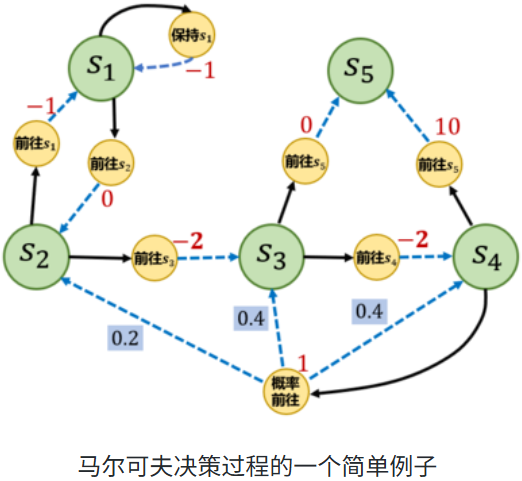
接下来我们将图中马尔可夫决策过程用代码表示，并且定义两个策略。第一个策略是一个随机策略，即在每个状态的时候，会以同样的概率选取他可能采取的动作，例如会在s1以0.5和0.5的概率选取动作“保持s1”和“前往s20.第二个策略是一个我们提前设定的一个策略。”

In [57]:
S = ["S1", "S2", "S3", "S4", "S5"]        # 状态State集合
A = ["保持S1", "前往S1", "前往S2", "前往S3", "前往S4", "前往S5", "概率前往"]        # 动作Action集合

# 定义状态转移函数
P = {
    "S1-保持S1-S1":1.0, "S1-前往S2-S2":1.0,
    "S2-前往S1-S1":1.0, "S2-前往S3-S3":1.0,
    "S3-前往S4-S4":1.0, "S3-前往S5-S5":1.0,
    "S4-前往S5-S5":1.0, "S4-概率前往-S2":0.2,
    "S4-概率前往-S3":0.4, "S4-概率前往-S4":0.4,
}

# 定义奖励函数
R = {
    "S1-保持S1":-1, "S1-前往S2":0,
    "S2-前往S1":-1, "S2-前往S3":-2,
    "S3-前往S4":-2, "S3-前往S5":0,
    "S4-前往S5":10, "S4-概率前往":1,
}

gamma = 0.5         # 折扣因子
MDP = (S, A, P, R, gamma)       # MDP五元组：(状态S, 动作A, 状态转移矩阵P, 奖励函数R, 折扣因子γ)

# 策略1：随机策略
Pi_1 = {
    "S1-保持S1":0.5, "S1-前往S2":0.5,
    "S2-前往S1":0.5, "S2-前往S3":0.5,
    "S3-前往S4":0.5, "S3-前往S5":0.5,
    "S4-前往S5":0.5, "S4-概率前往":0.5,
}

# 策略2
Pi_2 = {
    "S1-保持S1":0.6, "S1-前往S2":0.4,
    "S2-前往S1":0.3, "S2-前往S3":0.7,
    "S3-前往S4":0.5, "S3-前往S5":0.5,
    "S4-前往S5":0.1, "S4-概率前往":0.9,
}

# 把输入的两个字符串通过 "-" 连接，便于我们使用上述定义的 P, R 变量
def join(str1, str2):
    return str1 + '-' + str2

我们现在就用代码实现来用该方法计算用随机策略（也就是代码中的Pi_1）时的状态价值函数。为了简单起见，我们直接给出转化后的MRP的状态转移矩阵和奖励函数，同学们可以自行验证。

In [58]:
gamma = 0.5

# 转化后的MRP的状态转移矩阵
P_from_mdp_to_mrp = [
    [0.5, 0.5, 0.0, 0.0, 0.0],
    [0.5, 0.0, 0.5, 0.0, 0.0],
    [0.0, 0.0, 0.0, 0.5, 0.5],
    [0.0, 0.1, 0.2, 0.2, 0.5],
    [0.0, 0.0, 0.0, 0.0, 1.0],
]

P_from_mdp_to_mrp = np.array(P_from_mdp_to_mrp)
R_from_mdp_to_mrp = [-0.5, -1.5, -1.0, 5.5, 0]

V = compute(P_from_mdp_to_mrp, R_from_mdp_to_mrp, gamma, 5)
print("MDP中每个状态价值分别为：")
print(V)

MDP中每个状态价值分别为：
[[-1.22555411]
 [-1.67666232]
 [ 0.51890482]
 [ 6.0756193 ]
 [ 0.        ]]


## 蒙特卡洛方法（Monte-Carlo Methods）
接下来我们用代码定义一个采样函数，需要遵守状态转移矩阵和相应的策略，我们每次将 (s, a, r, s_next) 元组放入序列中，直到到达终止序列。然后我们通过该函数实现用随机策略在途中MDP实际采样几条序列。

In [59]:
# 参1：MDP五元组；参2：策略，通常是一个字典，键是(状态, 动作)的组合，值是该状态下选择该动作的概率；参3：限制最长时间步；参4：总共采样序列数
def sample(MDP, Pi, timestep_max, number):
    """
    按照给定的策略 Pi，在马尔可夫决策过程 MDP 中模拟智能体与环境交互，生成若干条完整的轨迹（episode）。每条轨迹是一串(s, a, r, s_next)元组
    """
    S, A, P, R, gamma = MDP     # 从MDP五元组中获取状态集、动作集、状态转移概率矩阵、奖励函数和折扣因子
    episodes = []     # 初始化存放所有序列的列表，episodes最终会包含 number条 episode，每条 episode是一个列表，里面是(s, a, r, s_next)
    for _ in range(number):     # 循环遍历number次，采样number条序列
        episode= []     # 用于记录当前这一条轨迹
        timestep = 0        # 记录步数
        s = S[np.random.randint(4)]     # 随机选择一个除S5以外的状态s作为起点
        while s != "S5" and timestep <= timestep_max:       # 当前状态为终止状态或时间步超过限制最长时间步时，一次采样结束
            timestep += 1       # 一个遍历对应一个时间步
            rand, temp = np.random.rand(), 0        # np.random.rand(): 生成一个 0~1 的随机数 rand；temp是累积概率，初始为 0
            # 在状态s根据策略选择动作
            for a_opt in A:     # 遍历所有可能的动作
                temp += Pi.get(join(s, a_opt), 0)       # 从策略 Pi 中取出在状态 s 下选择动作 a_opt 的概率，累加到 temp
                if temp > rand:     # 当累积概率 temp 超过随机数 rand 时
                    a = a_opt        # 选择当前动作 a_opt 作为动作 a
                    r = R.get(join(s, a), 0)        # 从奖励函数 R 中取出执行该动作后获得的即时奖励 r
                    break

            rand, temp = np.random.rand(), 0        # 初始化 rand, temp 变量
            # 根据状态转移概率得到下一个状态s_next
            for s_opt in S:     # 遍历所有可能的下一个状态
                temp += P.get(join(join(s, a), s_opt), 0)    # 从状态转移概率 P 中取出在状态 s 执行动作 a 后转移到 s_opt 的概率，累加
                if temp > rand:         # 累积概率超过 rand 时
                    s_next = s_opt      # 选中该 s_opt 作为下一个状态 s_next
                    break

            episode.append((s, a, r, s_next))       # 把当前步的 (状态, 动作, 奖励, 下一个状态) 加入当前轨迹
            s = s_next        # s_next变成当前状态，开始接下来的循环
        episodes.append(episode)        # 当 while 结束（到达终止状态或超时），把这条完整的 episode 放入 episodes。
    return episodes     # 返回所有轨迹（number条）

# 采样5次，每个序列最长不超过1000步
episodes = sample(MDP, Pi_1, 20, 5)
print("第1条序列：", episodes[0])
print("第2条序列：", episodes[1])
print("第5条序列：", episodes[4])

第1条序列： [('S4', '概率前往', 1, 'S2'), ('S2', '前往S1', -1, 'S1'), ('S1', '前往S2', 0, 'S2'), ('S2', '前往S3', -2, 'S3'), ('S3', '前往S5', 0, 'S5')]
第2条序列： [('S2', '前往S3', -2, 'S3'), ('S3', '前往S5', 0, 'S5')]
第5条序列： [('S2', '前往S1', -1, 'S1'), ('S1', '保持S1', -1, 'S1'), ('S1', '保持S1', -1, 'S1'), ('S1', '保持S1', -1, 'S1'), ('S1', '前往S2', 0, 'S2'), ('S2', '前往S1', -1, 'S1'), ('S1', '保持S1', -1, 'S1'), ('S1', '前往S2', 0, 'S2'), ('S2', '前往S3', -2, 'S3'), ('S3', '前往S5', 0, 'S5')]


In [60]:
# 对所有采样序列计算所有状态的价值
def MC(episodes, V, N, gamma):
    for episode in episodes:
        G = 0
        for i in range(len(episode) - 1, -1, -1):        # 等效于 for i in reversed(range(len(episode)))，一个序列从后往前计算
            (s, a, r, s_next) = episode[i]
            G = r + gamma * G
            N[s] += 1
            V[s] += (G - V[s]) / N[s]

timestep_max = 20

# 采样1000次
episodes = sample(MDP, Pi_1, timestep_max, 1000)
gamma = 0.5
V = {"S1":0, "S2":0, "S3":0, "S4":0, "S5":0}
N = {"S1":0, "S2":0, "S3":0, "S4":0, "S5":0}
MC(episodes, V, N, gamma)
print("使用蒙特卡洛方法计算MDP状态价值为：")
print(V)

使用蒙特卡洛方法计算MDP状态价值为：
{'S1': -1.203967717564448, 'S2': -1.701443586179187, 'S3': 0.4854125369247507, 'S4': 6.031122478413433, 'S5': 0}
